# E-Commerce en Brasil: Análisis de tiempos de entrega por estado





## Descripción general

Olist es una tienda que opera en todo Brasil, la logística de la tienda varía mucho en cada estado, por lo cual no es lo mismo los envíos realizados en São Paulo, que en Amazonas. En este proyecto se busca verificar en dónde están fallando las entregas, además de priorizar las mejoras.

## Desarrollo
### Ejecución de librerías

Para el desarrollo del proyecto, se contó con el uso de SQLite ejecutado desde pandas, además de cargar los 'datasets' para su investigación, e importándolos al entorno del notebook.


In [1]:
import os
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

# Carpeta con los archivos CSV
DATA_DIR = os.getcwd()

In [2]:
conn = sqlite3.connect('olist_data.db')

csvs = [f for f in os.listdir(DATA_DIR) if f.endswith('.csv')]
assert csvs, f'No se encontraron .csv en {DATA_DIR}. Ajusta DATA_DIR.'

for f in sorted(csvs):
    tabla = os.path.splitext(f)[0].replace(' ', '_').lower()
    pd.read_csv(os.path.join(DATA_DIR, f)).to_sql(tabla, conn, if_exists='replace', index=False)

def sql(query):
    return pd.read_sql_query(query, conn)

sql("""
SELECT 'orders' AS tabla, COUNT(*) AS filas FROM olist_orders_dataset UNION ALL
SELECT 'customers', COUNT(*) FROM olist_customers_dataset UNION ALL
SELECT 'order_items', COUNT(*) FROM olist_order_items_dataset UNION ALL
SELECT 'order_payments', COUNT(*) FROM olist_order_payments_dataset UNION ALL
SELECT 'order_reviews', COUNT(*) FROM olist_order_reviews_dataset UNION ALL
SELECT 'products', COUNT(*) FROM olist_products_dataset
""")

,tabla,filas
0,orders,99441
1,customers,99441
2,order_items,112650
3,order_payments,103886
4,order_reviews,99224
5,products,32951



### Limpieza y validación

En el desarrollo se ha encontrado pedidos cancelados mezclados con completados, las fechas vienen en 4 columnas distintas, y valores nulos en campos de entrega para pedidos no enviados. Filtrarlos es el primer paso. Además, las categorías de producto están portugués. Hay archivo de traducción incluido, pero el JOIN es manual, así que se decidió la realización del JOIN para una mejor comprensión


In [6]:
# Estatus de pedidos y cuáles tienen fecha de entrega

sql("""
SELECT order_status, 
    COUNT(*) AS pedidos,
    SUM(order_delivered_customer_date IS NOT NULL) AS con_fecha_entrega
FROM olist_orders_dataset 
GROUP BY order_status
ORDER BY pedidos DESC;
""")

,order_status,pedidos,con_fecha_entrega
0,delivered,96478,96470
1,shipped,1107,0
2,canceled,625,6
3,unavailable,609,0
4,invoiced,314,0
5,processing,301,0
6,created,5,0
7,approved,2,0


Hay 6 pedidos cancelados (`canceled`), y 8 pedidos sin fecha de entrega (`delivered`). Por ende se filtra por estatus *y* por fecha al filtrar sólo por fecha no nula, dejando visualizar los cancelados.

Con esto se centraliza la limpieza en una vista que usan todas las consultas siguientes.

In [7]:
conn.execute('DROP VIEW IF EXISTS v_entregados')
conn.execute("""
CREATE VIEW v_entregados AS
SELECT o.order_id,
       c.customer_state,
       o.order_purchase_timestamp,
       o.order_delivered_customer_date,
       o.order_estimated_delivery_date,
       julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)  AS dias_entrega,
       julianday(o.order_estimated_delivery_date) - julianday(o.order_purchase_timestamp)  AS dias_estimados,
       julianday(o.order_delivered_customer_date) - julianday(o.order_estimated_delivery_date) AS dias_vs_estimado,
       julianday(date(o.order_delivered_customer_date)) - julianday(date(o.order_estimated_delivery_date)) AS dias_retraso,
       date(o.order_delivered_customer_date) > date(o.order_estimated_delivery_date) AS tarde
FROM olist_orders_dataset o
JOIN olist_customers_dataset c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_estimated_delivery_date IS NOT NULL
""")

# Validaciones: tamaño, duraciones imposibles y extremos
sql("""
SELECT COUNT(*)                          AS pedidos,
       SUM(dias_entrega < 0)             AS entregas_antes_de_compra,
       ROUND(MIN(dias_entrega), 1)       AS min_dias,
       ROUND(AVG(dias_entrega), 1)       AS promedio_dias,
       ROUND(MAX(dias_entrega), 1)       AS max_dias,
       ROUND(AVG(tarde) * 100, 1)        AS pct_tarde
FROM v_entregados
""")

,pedidos,entregas_antes_de_compra,min_dias,promedio_dias,max_dias,pct_tarde
0,96470,0,0.5,12.6,209.6,6.8


No hay entregas anteriores a la compra. El máximo (≈210 días) es un valor atípico que se **mantiene**, porque es un caso real de entrega muy lenta y afecta a pocos pedidos; por eso se reporta también la mediana donde importa.

#### Decisiones de limpieza

Hay una tabla que compila las acciones realizadas para hacer la limpieza de los archivos
| Problema | Decisión |
|---|---|
| Pedidos cancelados/no disponibles mezclados | Solo `order_status = 'delivered'` |
| Nulos en fechas de entrega | Se excluyen los pedidos sin `order_delivered_customer_date` |
| Fechas como texto | Formato ISO, por lo que `julianday()` las interpreta bien; se valida más abajo |
| Retraso | Un pedido es tarde si la **fecha** de entrega es posterior a la **fecha** estimada (la estimada viene a las 00:00) |
| Categorías en portugués | `LEFT JOIN` con la tabla de traducción; sin categoría se etiqueta `sin_categoria` |
| Ingresos | `SUM(price)`, sin flete |
| Volumen | Pedidos distintos (`COUNT(DISTINCT order_id)`), no ítems |
| Reseñas duplicadas | Se promedian por pedido antes del JOIN |

### Tiempos de entrega por estado y la estimación original

Una vez realizada la limpieza de los archivos, se comenzó a identificar los problemas de entregas, en la cual se han hecho consultas que identifican los tiempos de entrega por estados, incluyendo promedio de días reales, estimados y diferencia entre ambos, así como porcentaje de pedidos entregados tarde su comparación con la estimación original, además de una graficación de las diferencias de cada entrega con las librerías de `matplotlib`

In [ ]:
# Cálculo de los tiempos de entrega por estado.

estados = sql("""
SELECT customer_state                       AS estado,
       COUNT(*)                             AS pedidos,
       ROUND(AVG(dias_entrega), 1)          AS real_dias,
       ROUND(AVG(dias_estimados), 1)        AS estimado_dias,
       ROUND(AVG(dias_vs_estimado), 1)      AS vs_estimado_dias,
       ROUND(AVG(tarde) * 100, 1)           AS pct_tarde
FROM v_entregados
GROUP BY customer_state
ORDER BY real_dias DESC
""")
estados

,estado,pedidos,real_dias,estimado_dias,vs_estimado_dias,pct_tarde
0,RR,41,29.4,46.0,-16.6,12.2
1,AP,67,27.2,46.2,-19.1,3.0
2,AM,145,26.4,45.3,-18.9,2.8
3,AL,397,24.5,32.6,-8.0,21.4
4,PA,946,23.8,37.2,-13.4,11.2
5,MA,717,21.6,30.5,-8.9,17.4
6,SE,335,21.5,30.8,-9.3,15.2
7,CE,1279,21.3,31.4,-10.1,13.8
8,AC,80,21.0,41.1,-20.1,3.8
9,PB,517,20.4,33.0,-12.6,10.4


In [13]:
# Mediana por estado (calculado en pandas)
med = (sql('SELECT customer_state AS estado, dias_entrega FROM v_entregados')
       .groupby('estado')['dias_entrega'].median().round(1).rename('mediana_real_dias'))
estados.merge(med, on='estado').sort_values('real_dias', ascending=False).head(10)

,estado,pedidos,real_dias,estimado_dias,vs_estimado_dias,pct_tarde,mediana_real_dias
0,RR,41,29.4,46.0,-16.6,12.2,25.0
1,AP,67,27.2,46.2,-19.1,3.0,24.3
2,AM,145,26.4,45.3,-18.9,2.8,25.9
3,AL,397,24.5,32.6,-8.0,21.4,22.3
4,PA,946,23.8,37.2,-13.4,11.2,21.1
5,MA,717,21.6,30.5,-8.9,17.4,19.2
6,SE,335,21.5,30.8,-9.3,15.2,18.0
7,CE,1279,21.3,31.4,-10.1,13.8,18.2
8,AC,80,21.0,41.1,-20.1,3.8,18.4
9,PB,517,20.4,33.0,-12.6,10.4,18.2


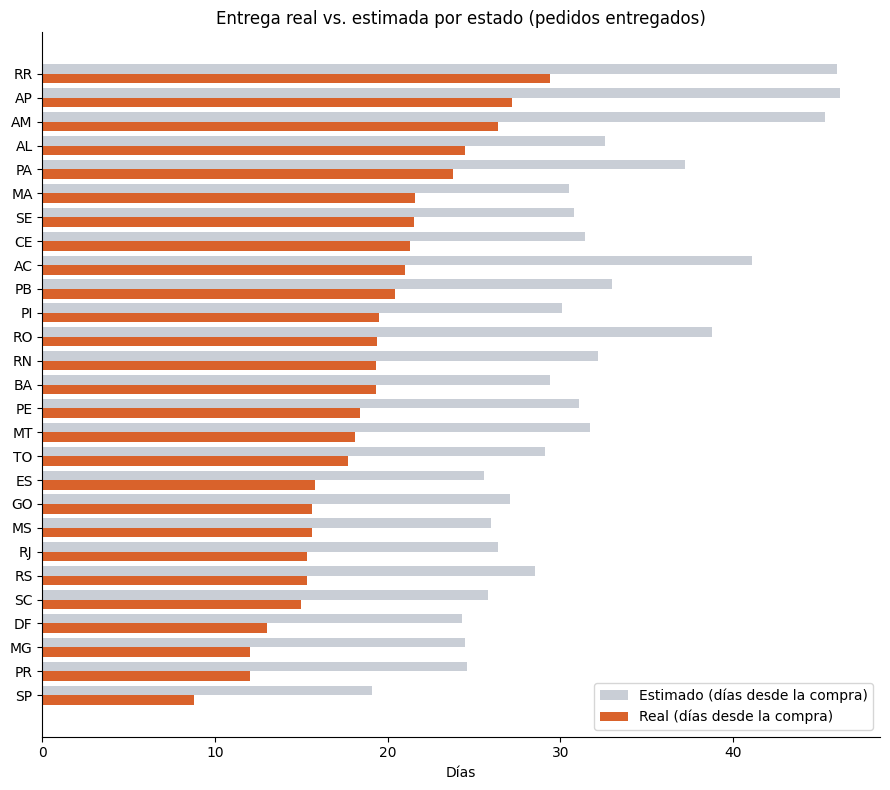

In [14]:
# Gráfico de barras horizontales comparando días estimados vs. reales por estado.

e = estados.sort_values('real_dias')
fig, ax = plt.subplots(figsize=(9, 8))
y = range(len(e))
ax.barh([i + 0.2 for i in y], e['estimado_dias'], 0.4, label='Estimado (días desde la compra)', color='#c9ced6')
ax.barh([i - 0.2 for i in y], e['real_dias'], 0.4, label='Real (días desde la compra)', color='#d9622b')
ax.set_yticks(list(y))
ax.set_yticklabels(e['estado'])
ax.set_xlabel('Días')
ax.set_title('Entrega real vs. estimada por estado (pedidos entregados)')
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

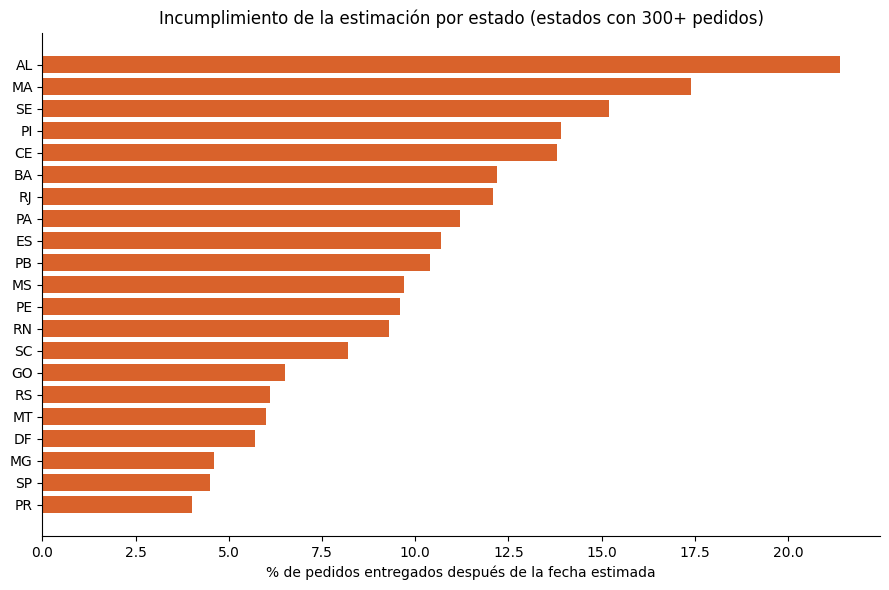

In [15]:
# Cumplimiento de la promesa: % de pedidos tarde por estado (solo estados con 300+ pedidos)
f = estados[estados['pedidos'] >= 300].sort_values('pct_tarde')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(f['estado'], f['pct_tarde'], color='#d9622b')
ax.set_xlabel('% de pedidos entregados después de la fecha estimada')
ax.set_title('Incumplimiento de la estimación por estado (estados con 300+ pedidos)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

#### Conclusiones:
- En términos absolutos: Roraima `RR` es el estado con **entregas más lentas (29.4 días)**, le siguen Amapá `AP` (27.2 días), Amazonas `AM` (26.4 días), Alagoas `AL` (24.5 días) y Paraíba `PA` (23.8 días). Sao Paulo `SP` es el más rápido con 8.8 días.
- Roraima `RR`, Amapá `AP` y Amazonas `AM` tienen estimaciones de más de 45 días y márgenes de 17 a 19 días: son lentos, pero la promesa es muy holgada, y el margen varía mucho. Por ende, **Todos los estados llegan en promedio antes de lo estimado**
- **Donde se rompe la promesa es en Alagoas `AL` (21.4% de pedidos tarde), Maranhão `MA` (17.4%) y Sergipe `SE` (15.2%).** Tienen tiempos medianos y estimaciones ajustadas, con márgenes de apenas 8 a 9 días. Son los estados que más se benefician de una mejora logística.
- **Río de Janeiro `RJ`** tiene 12.1% de pedidos tarde, alto para un estado con entregas relativamente rápidas y mucho volumen.
- **Limitación:** Roraima `RR` (41 pedidos), Amapá `AP` (67) y Acre `AC` (80) tienen muestras pequeñas; sus promedios son poco estables.

### Categorías con más ingresos

Al saber qué estados tienen problemas con entregas, se analizó cuales categorías generan más ingresos, para eso se hizo una consulta con COALESCE,para evaluar una lista de argumentos de los nombres en inglés con los de la tabla original, así devolviendo el primer valor no nulo. 

In [16]:
# ¿Qué categorías generan más ingresos?

categorias = sql("""
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'sin_categoria') AS categoria,
       ROUND(SUM(oi.price), 2)       AS ingresos,
       COUNT(*)                      AS items_vendidos,
       COUNT(DISTINCT oi.order_id)   AS pedidos
FROM olist_order_items_dataset oi
JOIN olist_orders_dataset o   ON oi.order_id = o.order_id AND o.order_status = 'delivered'
JOIN olist_products_dataset p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
GROUP BY categoria
""")
print('Categorías:', len(categorias))
categorias.sort_values('ingresos', ascending=False).head(10)

Categorías: 74


,categoria,ingresos,items_vendidos,pedidos
43,health_beauty,1233131.72,9465,8647
73,watches_gifts,1166176.98,5859,5495
7,bed_bath_table,1023434.76,10953,9272
68,sports_leisure,954852.55,8431,7530
15,computers_accessories,888724.61,7644,6530
39,furniture_decor,711927.69,8160,6307
49,housewares,615628.69,6795,5743
20,cool_stuff,610204.10,3718,3559
5,auto,578966.65,4140,3810
72,toys,471286.48,4030,3804


In [ ]:
# Consulta con la cantidad de pedidos por categoría (para ver cuáles son las más vendidas).

categorias.sort_values('pedidos', ascending=False).head(10)


,categoria,ingresos,items_vendidos,pedidos
7,bed_bath_table,1023434.76,10953,9272
43,health_beauty,1233131.72,9465,8647
68,sports_leisure,954852.55,8431,7530
15,computers_accessories,888724.61,7644,6530
39,furniture_decor,711927.69,8160,6307
49,housewares,615628.69,6795,5743
73,watches_gifts,1166176.98,5859,5495
71,telephony,309860.23,4430,4093
5,auto,578966.65,4140,3810
72,toys,471286.48,4030,3804


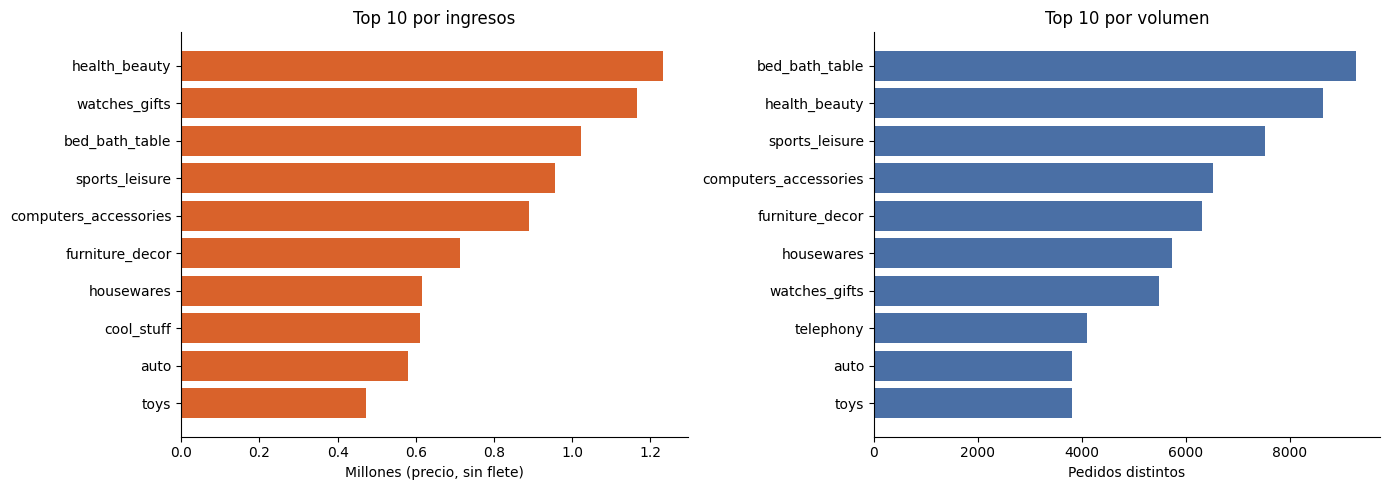

In [18]:
top_ing = categorias.nlargest(10, 'ingresos').sort_values('ingresos')
top_vol = categorias.nlargest(10, 'pedidos').sort_values('pedidos')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top_ing['categoria'], top_ing['ingresos'] / 1e6, color='#d9622b')
axes[0].set_title('Top 10 por ingresos')
axes[0].set_xlabel('Millones (precio, sin flete)')
axes[1].barh(top_vol['categoria'], top_vol['pedidos'], color='#4a6fa5')
axes[1].set_title('Top 10 por volumen')
axes[1].set_xlabel('Pedidos distintos')
for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [19]:
# Categoría nula: cuánto pesa
categorias[categorias['categoria'] == 'sin_categoria']

,categoria,ingresos,items_vendidos,pedidos
65,sin_categoria,170726.63,1537,1392


#### Conclusiones: categorías
- health_beauty (1.23 M), watches_gifts (1.17 M) y bed_bath_table (1.02 M) encabezan el ranking como las **Categorías con más ingresos:** .
- **Volumen:** bed_bath_table (9,272 pedidos) es la primera, seguida de health_beauty (8,647) y sports_leisure (7,530).
- watches_gifts es 2.ª en ingresos pero 7.ª en volumen (5,495 pedidos), por su ticket alto. bed_bath_table es 1.ª en volumen pero 3.ª en ingresos, en la que se ve un **Contraste de ticket:**
- **Limitación:** 1,537 ítems (1,392 pedidos) no tienen categoría; suman 170,727 en ingresos y quedan agrupados como `sin_categoria`.

### Reseñas y rangos de días

Aquí surge la cuestión,¿Si tiene relación los retrasos de entregas con las malas reseñas?, para averiguarlo, se hizo una consulta para identificar los pedidos, con el score promedio, para identificar las reseñas de 1 o 2 estrellas.

In [20]:
# Una fila por pedido: algunos pedidos tienen más de una reseña, se promedia antes del JOIN
reseñas = sql("""
WITH r AS (
    SELECT order_id, AVG(review_score) AS score
    FROM olist_order_reviews_dataset
    GROUP BY order_id
)
SELECT CASE WHEN v.tarde = 1 THEN 'tarde' ELSE 'a tiempo' END AS entrega,
       COUNT(*)                     AS pedidos,
       ROUND(AVG(r.score), 2)       AS score_promedio,
       ROUND(AVG(r.score <= 2) * 100, 1) AS pct_1_2_estrellas
FROM v_entregados v
JOIN r ON v.order_id = r.order_id
GROUP BY entrega
""")
reseñas

,entrega,pedidos,score_promedio,pct_1_2_estrellas
0,a tiempo,89443,4.29,9.2
1,tarde,6381,2.27,62.4


In [ ]:
# Pedidos por rango de días de retraso y su calificación promedio (solo pedidos entregados).

por_rango = sql("""
WITH r AS (
    SELECT order_id, AVG(review_score) AS score
    FROM olist_order_reviews_dataset
    GROUP BY order_id
)
SELECT CASE WHEN v.dias_retraso <= 0 THEN '0. A tiempo'
            WHEN v.dias_retraso <= 3 THEN '1. Retraso 1-3 días'
            WHEN v.dias_retraso <= 7 THEN '2. Retraso 4-7 días'
            ELSE '3. Retraso > 7 días' END AS rango,
       COUNT(*)                          AS pedidos,
       ROUND(AVG(r.score), 2)            AS score_promedio,
       ROUND(AVG(r.score <= 2) * 100, 1) AS pct_1_2_estrellas
FROM v_entregados v
JOIN r ON v.order_id = r.order_id
GROUP BY rango
ORDER BY rango
""")
por_rango

,rango,pedidos,score_promedio,pct_1_2_estrellas
0,0. A tiempo,89443,4.29,9.2
1,1. Retraso 1-3 días,1852,3.29,32.2
2,2. Retraso 4-7 días,1748,2.11,67.6
3,3. Retraso > 7 días,2781,1.70,79.2


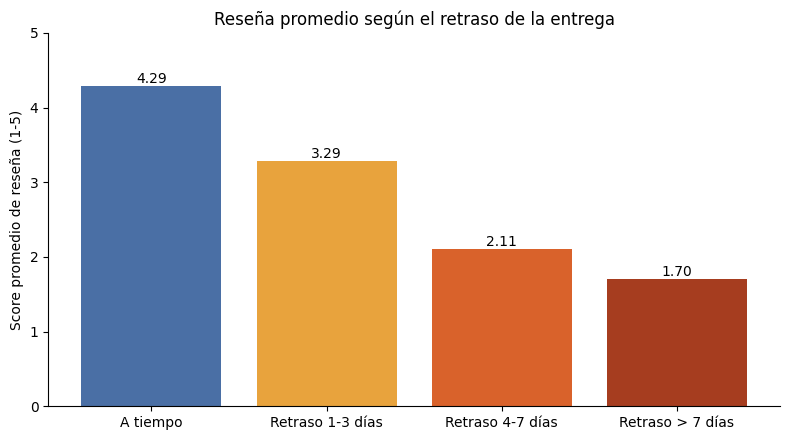

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
etiquetas = por_rango['rango'].str[3:]
barras = ax.bar(etiquetas, por_rango['score_promedio'], color=['#4a6fa5', '#e8a33d', '#d9622b', '#a63d1f'])
ax.bar_label(barras, fmt='%.2f')
ax.set_ylim(0, 5)
ax.set_ylabel('Score promedio de reseña (1-5)')
ax.set_title('Reseña promedio según el retraso de la entrega')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

#### Conclusiones: reseñas
- Los pedidos a tiempo tienen un score promedio de **4.29** (9.2% de reseñas de 1 o 2 estrellas); los tardíos, **2.27** (62.4%).
- La caída **crece con el retraso**: 3.29 con 1 a 3 días, 2.11 con 4 a 7 días y 1.70 con más de 7 días.
- Solo el 6.8% de los pedidos llega tarde, así que el problema es concentrado y atacable.
- Es una **asociación, no prueba causalidad**: otros factores (calidad del producto, por ejemplo) también pueden influir.

### Métodos de pago

Existen muchos métodos de pago que realiza la clientela, ¿Cuáles son los métodos de pago más preferidos? Se hizo una consulta en la que se relaciona los métodos de pago con los pedidos, y qué tan común son las cuotas promedio.

In [24]:
# Métodos de pago preferidos por la clientela

pagos = sql("""
SELECT payment_type                                   AS metodo,
       COUNT(DISTINCT order_id)                       AS pedidos,
       ROUND(COUNT(DISTINCT order_id) * 100.0 /
             (SELECT COUNT(DISTINCT order_id) FROM olist_order_payments_dataset), 1) AS pct_pedidos,
       ROUND(AVG(payment_installments), 1)            AS cuotas_promedio
FROM olist_order_payments_dataset
GROUP BY payment_type
ORDER BY pedidos DESC
""")
pagos

,metodo,pedidos,pct_pedidos,cuotas_promedio
0,credit_card,76505,76.9,3.5
1,boleto,19784,19.9,1.0
2,voucher,3866,3.9,1.0
3,debit_card,1528,1.5,1.0
4,not_defined,3,0.0,1.0


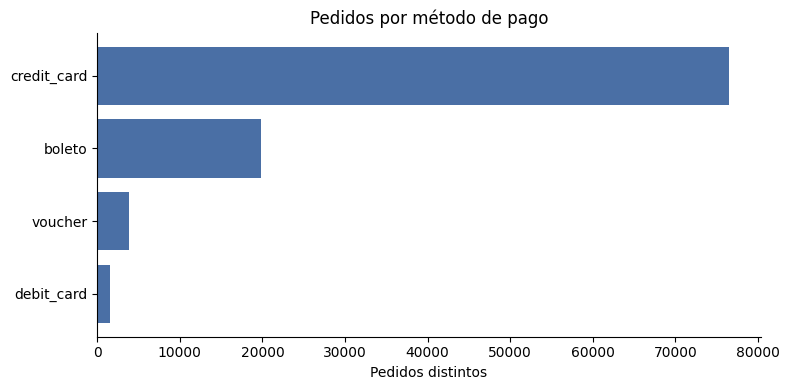

In [25]:
p = pagos[pagos['metodo'] != 'not_defined'].sort_values('pedidos')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(p['metodo'], p['pedidos'], color='#4a6fa5')
ax.set_xlabel('Pedidos distintos')
ax.set_title('Pedidos por método de pago')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

#### Conclusiones
- **Tarjeta de crédito** es la más populas, domina con 76,505 pedidos (76.9%) y es el único método con cuotas (3.5 en promedio).
- **Boleto** es el segundo (19.9%), seguido por voucher (3.9%) y tarjeta de débito (1.5%).
- Los porcentajes suman más de 100% porque un pedido puede combinar métodos (por ejemplo, tarjeta más voucher).
- `not_defined` (3 registros) se trata como anomalía y se excluye de la gráfica.

## Conclusion

### Hallazgos generales
1. **Dónde se entrega más lento:** RR, AP, AM, AL y PA, con 24 a 29 días en promedio frente a 8.8 de SP.
2. **Dónde se incumple la promesa:** AL, MA y SE, con 15% a 21% de pedidos tardíos, aunque en promedio lleguen antes de lo estimado. RR, AP y AM son lentos pero con estimaciones muy holgadas.
3. **Por qué importa:** un pedido tardío baja la reseña de 4.29 a 2.27 en promedio y a 1.70 si el retraso supera 7 días.
4. **Qué vende:** health_beauty y watches_gifts lideran ingresos; bed_bath_table lidera volumen.
5. **Cómo pagan:** 77% con tarjeta de crédito, casi siempre en cuotas.

### Recomendaciones

Enfocar en mejorar la logística en los estados en que se entrega lento, así como incentivar los diversos métodos de pago, sin descuidar los pagos con tarjeta de crédito y enfocar en los productos que más se venden, y los que no se venden tanto, realizar temporada de ofertas para aumentar las ventas.